# Ejercicio Regression Tree
Son datos de temperaturas tomados de la ciudad de Seattle. El objetivo es intentar predecir lo mejor posible la máxima temperatura (columna `actual`) que alcanzaremos al día siguiente. Para ello contaremos con temperaturas de los dos días anteriores, históricos de máximas temperaturas y un amigo bastante chapas que te da su predicción del tiempo cada día.

**Resumen de datos**:
* year: 2016 for all data points
* month: number for month of the year
* day: number for day of the year
* week: day of the week as a character string
* temp_2: max temperature 2 days prior
* temp_1: max temperature 1 day prior
* average: historical average max temperature
* actual: max temperature measurement
* friend: your friend’s prediction, a random number between 20 below the average and 20 above the average


### 1. Importa el csv "temps.csv"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df = pd.read_csv("data/temps.csv")
df.head()

,year,month,day,week,temp_2,temp_1,average,actual,friend
0,2016,1,1,Fri,45,45,45.6,45,29
1,2016,1,2,Sat,44,45,45.7,44,61
2,2016,1,3,Sun,45,44,45.8,41,56
3,2016,1,4,Mon,44,41,45.9,40,53
4,2016,1,5,Tues,41,40,46.0,44,41


### 2. Realiza un análisis exploratorio junto con un Feature Engineering

In [15]:
# 1. Revisamos tipos de datos y si hay celdas vacías (nulos)
print("--- INFORMACIÓN GENERAL ---")
df.info()

print("\n--- RESUMEN ESTADÍSTICO ---")
print(df.describe().round(2))

# 2. FEATURE ENGINEERING (Preparar los datos para que el ordenador los entienda)
# A) Eliminamos 'year' porque todos los datos son de 2016 (un dato que nunca cambia no aporta pistas)
df_limpio = df.drop(columns=['year'])

# B) Convertimos la columna de texto 'week' ('Mon', 'Tue'...) en columnas de ceros y unos (0 y 1)
df_limpio = pd.get_dummies(df_limpio, columns=['week'], dtype=int)

print("\n--- NUEVAS COLUMNAS TRAS FEATURE ENGINEERING ---")
print(df_limpio.head())

--- INFORMACIÓN GENERAL ---
<class 'pandas.DataFrame'>
RangeIndex: 348 entries, 0 to 347
Data columns (total 9 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   year     348 non-null    int64  
 1   month    348 non-null    int64  
 2   day      348 non-null    int64  
 3   week     348 non-null    str    
 4   temp_2   348 non-null    int64  
 5   temp_1   348 non-null    int64  
 6   average  348 non-null    float64
 7   actual   348 non-null    int64  
 8   friend   348 non-null    int64  
dtypes: float64(1), int64(7), str(1)
memory usage: 25.8 KB

--- RESUMEN ESTADÍSTICO ---
         year   month     day  temp_2  temp_1  average  actual  friend
count   348.0  348.00  348.00  348.00  348.00   348.00  348.00  348.00
mean   2016.0    6.48   15.51   62.65   62.70    59.76   62.54   60.03
std       0.0    3.50    8.77   12.17   12.12    10.53   11.79   15.63
min    2016.0    1.00    1.00   35.00   35.00    45.10   35.00   28.00
25%    2016.0    3

### 3. Selecciona variables y divide en train y test

In [16]:
from sklearn.model_selection import train_test_split

# X = Todas las pistas (todas las columnas menos 'actual')
X = df_limpio.drop(columns=['actual'])

# y = Lo que queremos adivinar (la temperatura máxima real)
y = df_limpio['actual']

# Dividimos en 75% para estudiar (train) y 25% para el examen final (test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

print("Días para estudiar (train):", X_train.shape)
print("Días para examinar (test): ", X_test.shape)

Días para estudiar (train): (261, 13)
Días para examinar (test):  (87, 13)


### 4. Entrena el modelo


In [17]:
from sklearn.tree import DecisionTreeRegressor

# Creamos el árbol de regresión (sin ponerle límite de preguntas)
arbol_sin_limite = DecisionTreeRegressor(random_state=42)

# Entrenamos el modelo con los datos de estudio
arbol_sin_limite.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with

### 5. Evaluación de tu modelo
Calcula el coeficiente de determinación. 

Calcula el MAE, MAPE, MSE y RMSE.

In [18]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error
)

# Hacemos predicciones tanto en estudio (train) como en examen (test)
pred_train = arbol_sin_limite.predict(X_train)
pred_test = arbol_sin_limite.predict(X_test)

# Calculamos las métricas en el examen (test)
r2_tr = r2_score(y_train, pred_train)
r2_te = r2_score(y_test, pred_test)
mae = mean_absolute_error(y_test, pred_test)
mape = mean_absolute_percentage_error(y_test, pred_test)
mse = mean_squared_error(y_test, pred_test)
rmse = np.sqrt(mse)

print("--- EVALUACIÓN DEL ÁRBOL SIN LÍMITE ---")
print(f"R² en Estudio (Train): {r2_tr:.4f}  <-- ¡Cuidado! 1.0000 significa que se lo sabe de memoria")
print(f"R² en Examen (Test):   {r2_te:.4f}")
print(f"MAE (Error medio):     {mae:.2f} °F")
print(f"MAPE (% de error):     {mape * 100:.2f} %")
print(f"MSE:                   {mse:.2f}")
print(f"RMSE:                  {rmse:.2f} °F")

--- EVALUACIÓN DEL ÁRBOL SIN LÍMITE ---
R² en Estudio (Train): 1.0000  <-- ¡Cuidado! 1.0000 significa que se lo sabe de memoria
R² en Examen (Test):   0.6105
MAE (Error medio):     5.48 °F
MAPE (% de error):     8.47 %
MSE:                   54.17
RMSE:                  7.36 °F


### 6. Representa el árbol de decisión

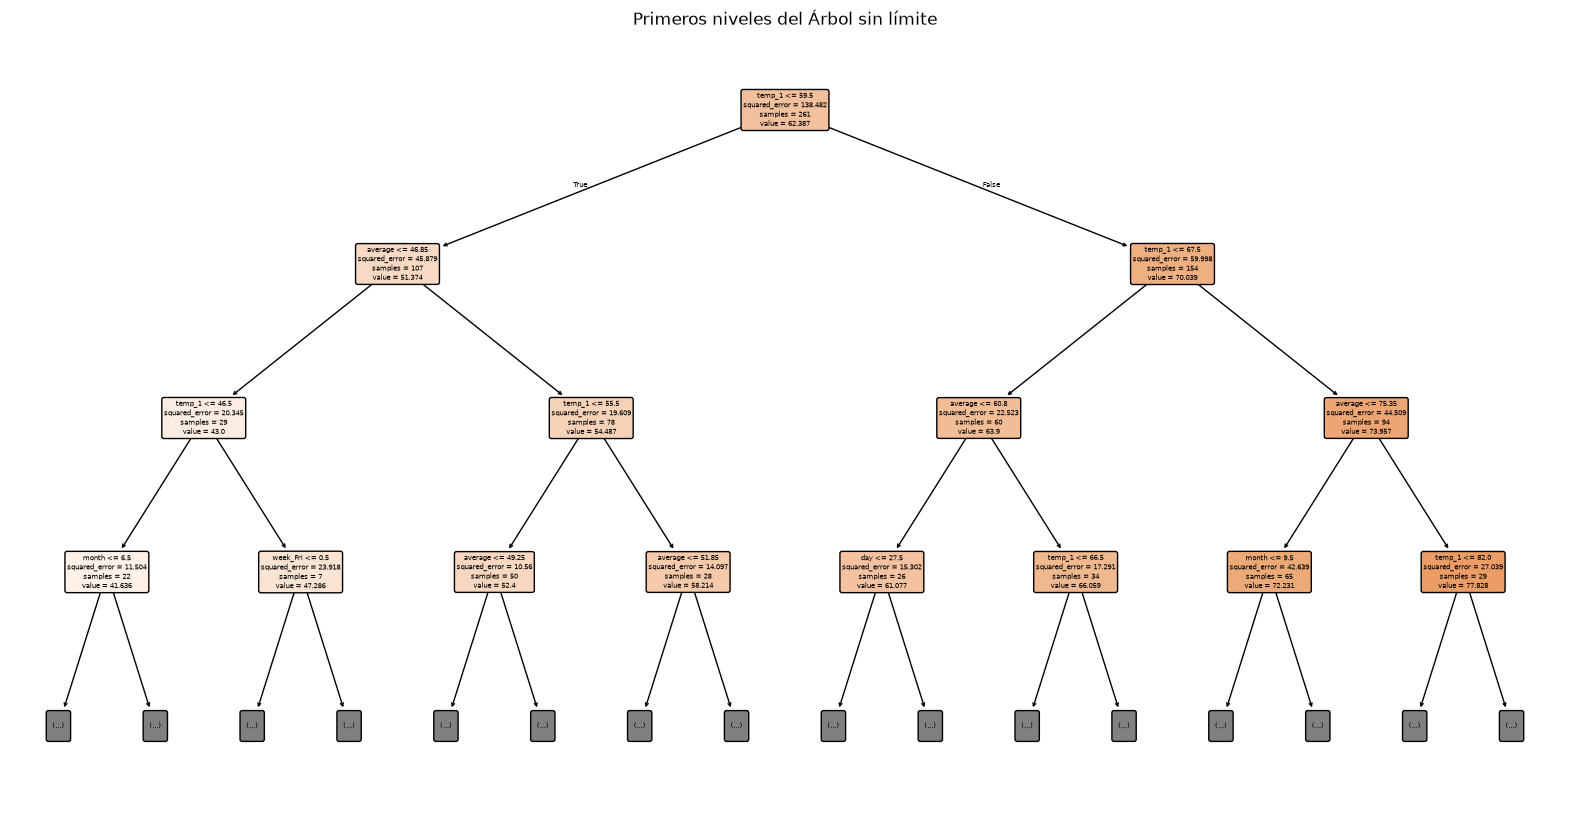

In [19]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(
    arbol_sin_limite,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    max_depth=3  # Limitamos visualmente a 3 niveles para que no se congele la pantalla
)
plt.title("Primeros niveles del Árbol sin límite")
plt.show()

### 7. Modifica el max_depth a 3 y vuelve a entrenarlo

In [20]:
# Creamos un árbol nuevo obligándole a hacer como máximo 3 preguntas seguidas (max_depth=3)
arbol_depth3 = DecisionTreeRegressor(max_depth=3, random_state=42)

# Entrenamos de nuevo
arbol_depth3.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

### 8. Vuelve a evaluar tu modelo

In [21]:
pred_train_3 = arbol_depth3.predict(X_train)
pred_test_3 = arbol_depth3.predict(X_test)

print("--- EVALUACIÓN DEL ÁRBOL CON MAX_DEPTH = 3 ---")
print(f"R² en Estudio (Train): {r2_score(y_train, pred_train_3):.4f}")
print(f"R² en Examen (Test):   {r2_score(y_test, pred_test_3):.4f}")
print(f"MAE:                   {mean_absolute_error(y_test, pred_test_3):.2f} °F")
print(f"MAPE:                  {mean_absolute_percentage_error(y_test, pred_test_3) * 100:.2f} %")
print(f"MSE:                   {mean_squared_error(y_test, pred_test_3):.2f}")
print(f"RMSE:                  {np.sqrt(mean_squared_error(y_test, pred_test_3)):.2f} °F")

--- EVALUACIÓN DEL ÁRBOL CON MAX_DEPTH = 3 ---
R² en Estudio (Train): 0.8372
R² en Examen (Test):   0.7923
MAE:                   4.11 °F
MAPE:                  6.53 %
MSE:                   28.88
RMSE:                  5.37 °F


### 9. Vuelve a representar su árbol

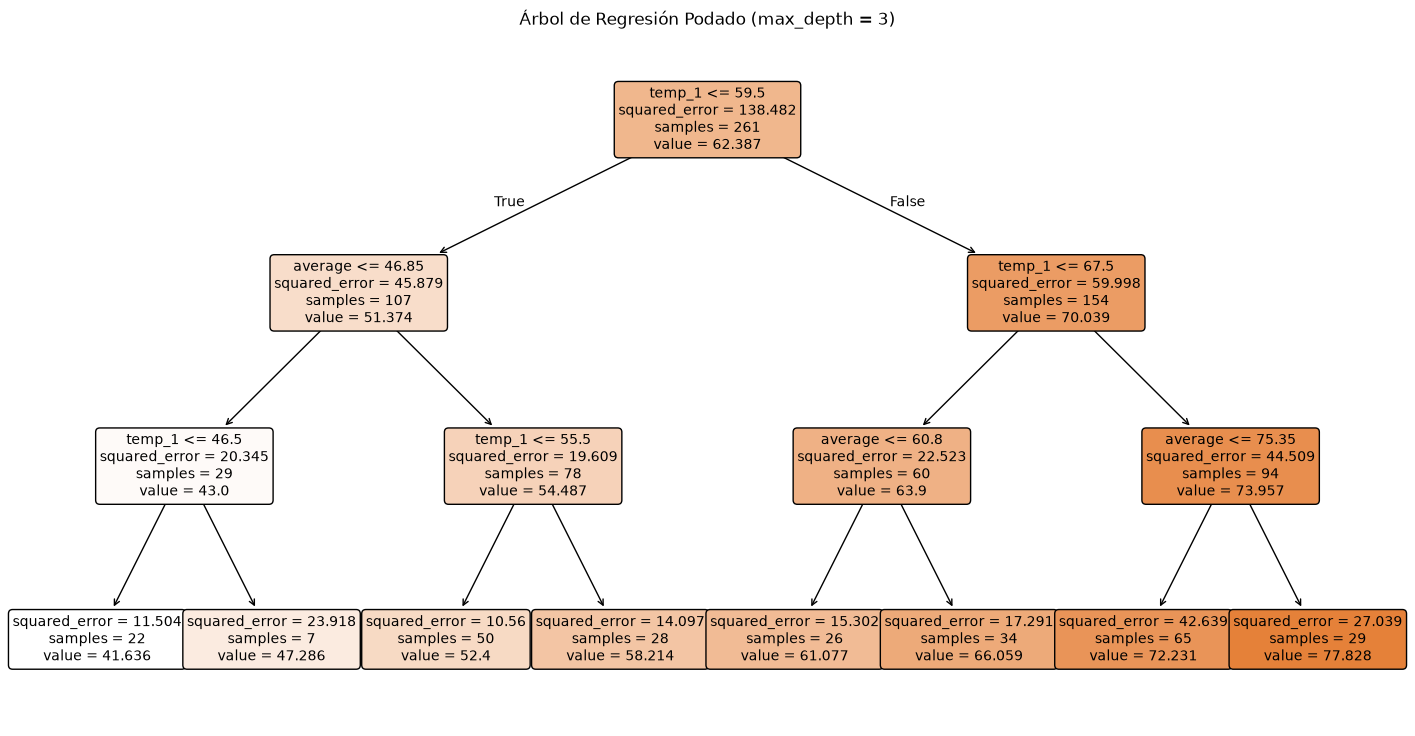

In [22]:
plt.figure(figsize=(18, 9))
plot_tree(
    arbol_depth3,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Árbol de Regresión Podado (max_depth = 3)")
plt.show()

### 10. Utiliza un grid search con cross validation para hiperparametrizar tu modelo

In [23]:
from sklearn.model_selection import GridSearchCV

# Definimos la parrilla de configuraciones que queremos probar
parrilla_parametros = {
    'max_depth': [2, 3, 4, 5, 6],          # Profundidad máxima del árbol
    'min_samples_split': [2, 5, 10, 20],   # Mínimo de días para poder dividir una caja
    'min_samples_leaf': [1, 2, 4, 8]       # Mínimo de días que debe tener una hoja final
}

# Probamos todas las combinaciones haciendo 5 exámenes cruzados (cv=5)
grid_reg = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=parrilla_parametros,
    cv=5,
    scoring='neg_mean_absolute_error'
)

grid_reg.fit(X_train, y_train)

# Nos quedamos con el árbol ganador
mejor_arbol_reg = grid_reg.best_estimator_

print("Mejor configuración encontrada:", grid_reg.best_params_)
print(f"R² en Test del mejor árbol:    {r2_score(y_test, mejor_arbol_reg.predict(X_test)):.4f}")
print(f"MAE en Test del mejor árbol:   {mean_absolute_error(y_test, mejor_arbol_reg.predict(X_test)):.2f} °F")

Mejor configuración encontrada: {'max_depth': 4, 'min_samples_leaf': 8, 'min_samples_split': 2}
R² en Test del mejor árbol:    0.8123
MAE en Test del mejor árbol:   3.93 °F


### 11. Obten el `feature_importances` de cada variable en el último modelo

--- IMPORTANCIA DE CADA VARIABLE (0 a 1) ---
temp_1        0.8599
average       0.1383
temp_2        0.0018
month         0.0000
day           0.0000
friend        0.0000
week_Fri      0.0000
week_Mon      0.0000
week_Sat      0.0000
week_Sun      0.0000
week_Thurs    0.0000
week_Tues     0.0000
week_Wed      0.0000
dtype: float64


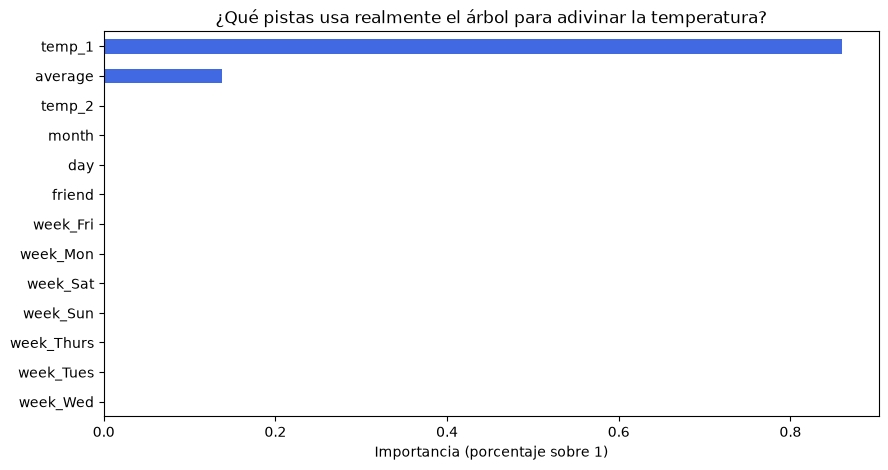

In [24]:
# Extraemos la importancia de cada columna y la ordenamos de mayor a menor
importancias = pd.Series(
    mejor_arbol_reg.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("--- IMPORTANCIA DE CADA VARIABLE (0 a 1) ---")
print(importancias.round(4))

# Lo dibujamos en un gráfico de barras horizontal
plt.figure(figsize=(10, 5))
importancias.plot(kind='barh', color='royalblue')
plt.gca().invert_yaxis() # Pone la más importante arriba
plt.title("¿Qué pistas usa realmente el árbol para adivinar la temperatura?")
plt.xlabel("Importancia (porcentaje sobre 1)")
plt.show()

### 12. Construye un nuevo modelo `DecisionTreeClassifier` que te clasifique cuando en un día va a hacer una temperatura mayor a 15ºC (59ºF). ¡Deberá tratarse como un problema de **clasificación**! Utiliza un grid search con cross validation y evalúa el mejor modelo.

Reparto de días (0 = Frío/Templado <=15°C, 1 = Cálido >15°C):
actual
1    204
0    144
Name: count, dtype: int64

Mejor configuración Clasificador: {'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 5}
Accuracy (Porcentaje de acierto global): 88.51%

--- REPORTE DETALLADO ---
              precision    recall  f1-score   support

 <= 15°C (0)       0.96      0.75      0.84        36
  > 15°C (1)       0.85      0.98      0.91        51

    accuracy                           0.89        87
   macro avg       0.91      0.87      0.88        87
weighted avg       0.90      0.89      0.88        87



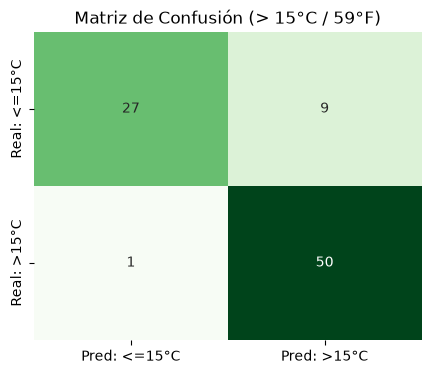

In [25]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Creamos la nueva variable objetivo binaria: 1 si supera 59°F (15°C), 0 si no
y_clasificacion = (df_limpio['actual'] > 59).astype(int)

print("Reparto de días (0 = Frío/Templado <=15°C, 1 = Cálido >15°C):")
print(y_clasificacion.value_counts())

# 2. Dividimos en train y test (stratify mantiene la misma proporción de días cálidos en ambos grupos)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_clasificacion, test_size=0.25, random_state=42, stratify=y_clasificacion
)

# 3. Buscamos el mejor árbol clasificador con GridSearchCV
parrilla_clf = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [2, 3, 4, 5, 6],
    'min_samples_leaf': [1, 2, 5, 10]
}

grid_clf = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=parrilla_clf,
    cv=5,
    scoring='accuracy'
)

grid_clf.fit(X_train_c, y_train_c)
mejor_clasificador = grid_clf.best_estimator_

# 4. Evaluamos el mejor modelo en el examen (test)
pred_c = mejor_clasificador.predict(X_test_c)

print("\nMejor configuración Clasificador:", grid_clf.best_params_)
print(f"Accuracy (Porcentaje de acierto global): {accuracy_score(y_test_c, pred_c) * 100:.2f}%")

print("\n--- REPORTE DETALLADO ---")
print(classification_report(y_test_c, pred_c, target_names=['<= 15°C (0)', '> 15°C (1)']))

# 5. Dibujamos la Matriz de Confusión
cm = confusion_matrix(y_test_c, pred_c)
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Greens', cbar=False,
    xticklabels=['Pred: <=15°C', 'Pred: >15°C'],
    yticklabels=['Real: <=15°C', 'Real: >15°C']
)
plt.title("Matriz de Confusión (> 15°C / 59°F)")
plt.show()